# Control óptimo de EDOs — Clase 1
**Repaso de EDOs y sistemas de control**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


## 0. Preparación

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Euler vs. Runge–Kutta 4
Resolvemos $\dot x = t^{-2}(tx - x^2)$, $x(1)=2$ en $[1,3]$, cuya solución exacta es $x(t)=t/(\tfrac12+\ln t)$
(ejercicio 4 del laboratorio de Aronna).

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

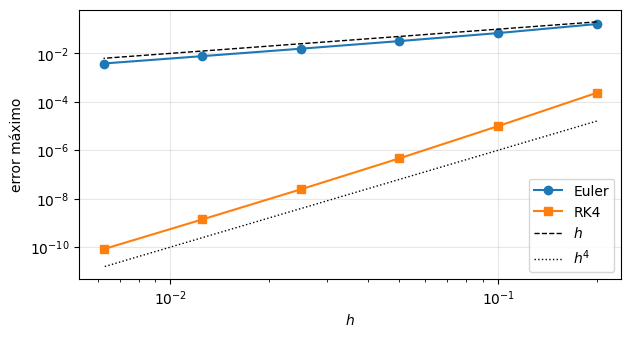

Orden estimado Euler: 1.0744022192121387
Orden estimado RK4  : 4.283103013801536


In [3]:
f = lambda t, x: t**-2*(t*x - x**2)
exacta = lambda t: t/(0.5 + np.log(t))

def euler(F, x0, t):
    x = np.zeros(len(t)); x[0] = x0
    for k in range(len(t) - 1):
        x[k+1] = x[k] + (t[k+1] - t[k])*F(t[k], x[k])
    return x

Ns = [10, 20, 40, 80, 160, 320]
err_e, err_r = [], []
for N in Ns:
    t = np.linspace(1, 3, N+1)
    err_e.append(np.abs(euler(f, 2.0, t) - exacta(t)).max())
    err_r.append(np.abs(rk4(f, 2.0, t)[:, 0] - exacta(t)).max())
hs = 2/np.array(Ns)
plt.loglog(hs, err_e, 'o-', label='Euler'); plt.loglog(hs, err_r, 's-', label='RK4')
plt.loglog(hs, hs, 'k--', lw=1, label='$h$'); plt.loglog(hs, 0.01*hs**4, 'k:', lw=1, label='$h^4$')
plt.xlabel('$h$'); plt.ylabel('error máximo'); plt.legend(); plt.show()
print('Orden estimado Euler:', np.polyfit(np.log(hs), np.log(err_e), 1)[0])
print('Orden estimado RK4  :', np.polyfit(np.log(hs), np.log(err_r), 1)[0])

## 2. `solve_ivp`: logística, SIR y explosión en tiempo finito
En la práctica se usa `scipy.integrate.solve_ivp` (paso adaptativo).

solve_ivp: Required step size is less than spacing between numbers. | último t alcanzado = 1.5707964965878372 (π/2 = 1.5707963267948966 )


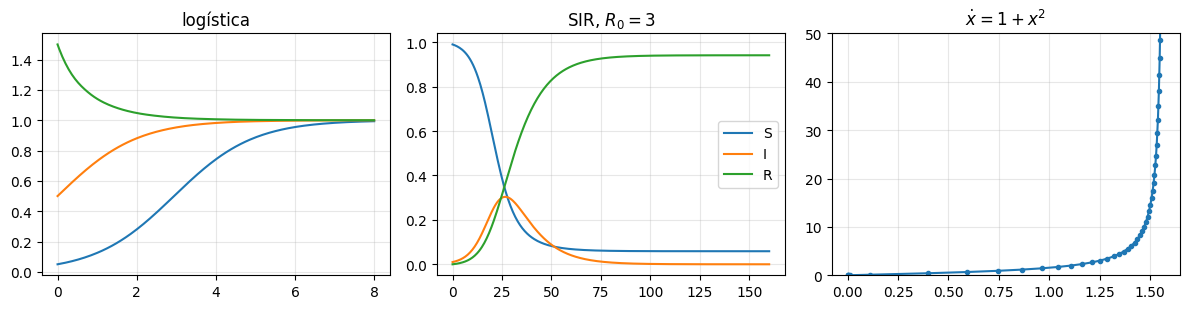

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for x0 in [0.05, 0.5, 1.5]:
    s = solve_ivp(lambda t, x: x*(1 - x), [0, 8], [x0], dense_output=True)
    tt = np.linspace(0, 8, 200); ax[0].plot(tt, s.sol(tt)[0])
ax[0].set_title('logística')

beta, gamma = 0.3, 0.1
s = solve_ivp(lambda t, y: [-beta*y[0]*y[1], beta*y[0]*y[1] - gamma*y[1], gamma*y[1]],
              [0, 160], [0.99, 0.01, 0], dense_output=True, rtol=1e-8)
tt = np.linspace(0, 160, 400)
for i, lab in enumerate('SIR'): ax[1].plot(tt, s.sol(tt)[i], label=lab)
ax[1].legend(); ax[1].set_title('SIR, $R_0=3$')

s = solve_ivp(lambda t, x: 1 + x**2, [0, 2], [0.0], rtol=1e-8)
ax[2].plot(s.t, s.y[0], '.-'); ax[2].set_ylim(0, 50); ax[2].set_title(r'$\dot x = 1+x^2$')
print('solve_ivp:', s.message, '| último t alcanzado =', s.t[-1], '(π/2 =', np.pi/2, ')')
plt.tight_layout(); plt.show()

## 3. Simular un sistema controlado
Un sistema de control es una EDO $\dot x = f(t, x, u(t))$ donde **nosotros elegimos** la función $u$.
Escribimos una función genérica que simula y calcula el funcional $J(u)=\int_0^T L\,dt$.

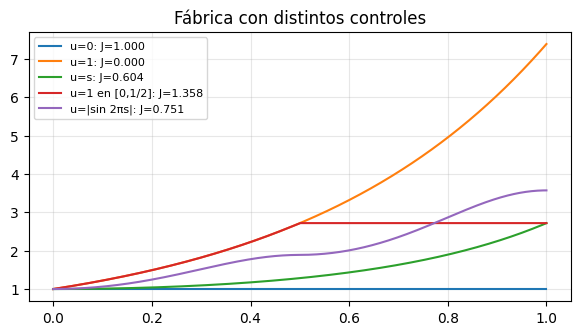

In [5]:
def simular(f, u, x0, T, L=None, N=1000):
    """f(t,x,u), u(t) función del tiempo. Devuelve t, x y (opcional) J = ∫ L(t,x,u) dt."""
    t = np.linspace(0, T, N+1)
    x = rk4(lambda s, y: f(s, y, u(s)), x0, t)
    if L is None:
        return t, x
    v = np.array([L(t[k], x[k], u(t[k])) for k in range(N+1)])
    return t, x, float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

# Fábrica: x' = 2 u(t) x, ganancia neta J = ∫ (1 - u) x dt
f_fab = lambda t, x, a: 2*a*x
L_fab = lambda t, x, a: (1 - a)*x[0]
controles = {'u=0': lambda s: 0.0, 'u=1': lambda s: 1.0, 'u=s': lambda s: s,
             'u=1 en [0,1/2]': lambda s: 1.0*(s <= 0.5), 'u=|sin 2πs|': lambda s: abs(np.sin(2*np.pi*s))}
for nombre, a in controles.items():
    t, x, J = simular(f_fab, a, 1.0, 1.0, L_fab)
    plt.plot(t, x[:, 0], label=f'{nombre}: J={J:.3f}')
plt.legend(fontsize=8); plt.title('Fábrica con distintos controles'); plt.show()

**Ejercicio 4 de la Clase 1.** Para $u=\mathbb 1_{[0,\tau]}$ se tiene $J(\tau)=(1-\tau)e^{2\tau}$. Lo verificamos numéricamente
y buscamos el mejor $\tau$.

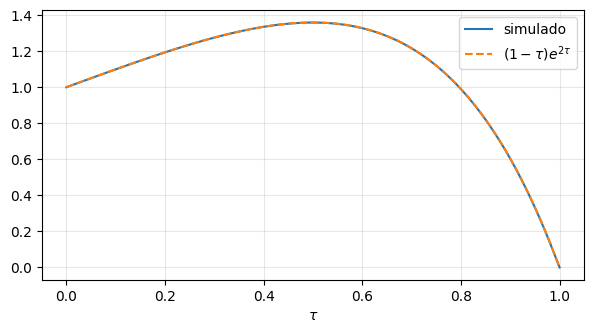

mejor tau ≈ 0.5


In [6]:
taus = np.linspace(0, 1, 101)
Js = [simular(f_fab, (lambda s, tau=tau: 1.0*(s <= tau)), 1.0, 1.0, L_fab, N=2000)[2] for tau in taus]
plt.plot(taus, Js, label='simulado'); plt.plot(taus, (1 - taus)*np.exp(2*taus), '--', label='$(1-\\tau)e^{2\\tau}$')
plt.xlabel(r'$\tau$'); plt.legend(); plt.show()
print('mejor tau ≈', taus[np.argmax(Js)])

## 4. Controlabilidad: test de Kalman y control de mínima energía
$\dot x = Ax+Bu$ es controlable sii $\operatorname{rg}[B\ AB\ \cdots\ A^{n-1}B]=n$.

In [7]:
def kalman(A, B):
    A = np.atleast_2d(A); B = np.array(B, float).reshape(A.shape[0], -1)
    n = A.shape[0]
    C = np.hstack([np.linalg.matrix_power(A, k) @ B for k in range(n)])
    return np.linalg.matrix_rank(C), C

ejemplos = {'carro a cohete': ([[0, 1], [0, 0]], [0, 1]),
            'dos poblaciones iguales': ([[1, 0], [0, 1]], [1, 1]),
            'péndulo invertido': ([[0, 1], [1, 0]], [0, 1]),
            'oscilador, B=(1,0)': ([[0, 1], [-1, 0]], [1, 0])}
for nombre, (A, B) in ejemplos.items():
    r, _ = kalman(np.array(A, float), B)
    print(f'{nombre:25s} rango = {r}  ->', 'controlable' if r == 2 else 'NO controlable')

carro a cohete            rango = 2  -> controlable
dos poblaciones iguales   rango = 1  -> NO controlable
péndulo invertido         rango = 2  -> controlable
oscilador, B=(1,0)        rango = 2  -> controlable


Carro a cohete: control de mínima energía con el Gramiano ($U=\mathbb R$), llevando $(1,0)$ al origen en $T=2$: $u(s)=B^\top e^{A^\top(T-s)}W_T^{-1}(x^1-e^{AT}x^0)$,
con $W_T=\int_0^T e^{As}BB^\top e^{A^\top s}ds$.

In [8]:
from scipy.linalg import expm
A = np.array([[0., 1.], [0., 0.]]); B = np.array([[0.], [1.]])
T, x0, x1 = 2.0, np.array([1., 0.]), np.zeros(2)
ss = np.linspace(0, T, 2001)
Ws = np.array([expm(A*s) @ B @ B.T @ expm(A.T*s) for s in ss])
W = np.sum(0.5*(Ws[1:] + Ws[:-1]), axis=0) * (ss[1] - ss[0])   # trapecio
eta = np.linalg.solve(W, x1 - expm(A*T) @ x0)
u_me = lambda s: (B.T @ expm(A.T*(T - s)) @ eta)[0]
print('u(0) =', u_me(0), ' (teoría: -1.5, ¡no respeta |u|<=1!);  u(1) =', u_me(1), ' (teoría: 0)')
t, x = simular(lambda t, x, u: A @ x + B[:, 0]*u, u_me, x0, T)
print('x(T) =', x[-1], '  (objetivo (0, 0))')

u(0) = -1.499999250000364  (teoría: -1.5, ¡no respeta |u|<=1!);  u(1) = 0.0  (teoría: 0)
x(T) = [ 4.99999758e-07 -4.90059382e-17]   (objetivo (0, 0))


## 5. Conjunto alcanzable por muestreo
Carro a cohete con $|u|\le 1$, $T=1$, desde el origen: sorteamos controles constantes a trozos y graficamos $x(T)$.

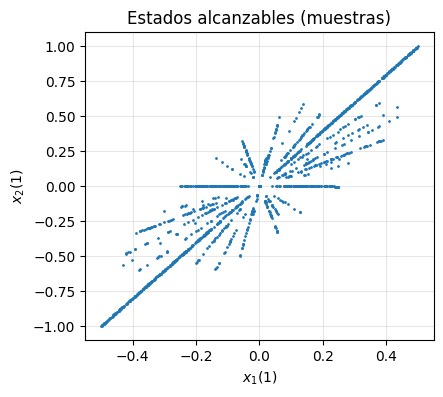

In [9]:
rng = np.random.default_rng(1)
puntos = []
for _ in range(1500):
    valores = rng.choice([-1, 1], size=rng.integers(1, 6)) * rng.uniform(0.3, 1, 1)
    u = lambda s, v=valores: v[min(int(s*len(v)), len(v) - 1)]
    t, x = simular(lambda t, x, u: np.array([x[1], u]), u, np.zeros(2), 1.0, N=200)
    puntos.append(x[-1])
P = np.array(puntos)
plt.figure(figsize=(4.5, 4)); plt.plot(P[:, 0], P[:, 1], '.', ms=2)
plt.xlabel('$x_1(1)$'); plt.ylabel('$x_2(1)$'); plt.title('Estados alcanzables (muestras)'); plt.show()

## Para explorar
1. Cambiar $T$ en la sección 5. ¿Cómo crece el conjunto alcanzable?
2. **Desafío:** el borde del conjunto alcanzable se obtiene con controles bang-bang con *una* conmutación.
   Calcular $x(1)$ para $u=+1$ en $[0,\tau]$ y $u=-1$ en $(\tau,1]$ y superponerlo al gráfico.
3. Probar el test de Kalman con un sistema de 3 estados (p. ej. tres tanques en serie).